<a href="https://colab.research.google.com/github/Vitela-debug/Colab_S1_Clase-de-progralaci-n_273522_TVB/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos_i_273522pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

**Tania Vitela Barraza**


**273522**

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATOS ORIGINALES:


,id,name,salary,cost,public,location
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE
1,2,Harvard University,121000,189600,Private,NE
2,3,Dartmouth College,123000,188400,Private,NE
3,4,Princeton University,123000,188700,Private,NE
4,5,Yale University,110000,194200,Private,NE


COLUMNAS SELECCIONADAS:


,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


TIPOS DE DATOS:
salary         int64
cost           int64
location    category
dtype: object
ESTADÍSTICAS DESCRIPTIVAS:


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000


CANTIDAD DE REGISTROS POR LOCALIDAD:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64


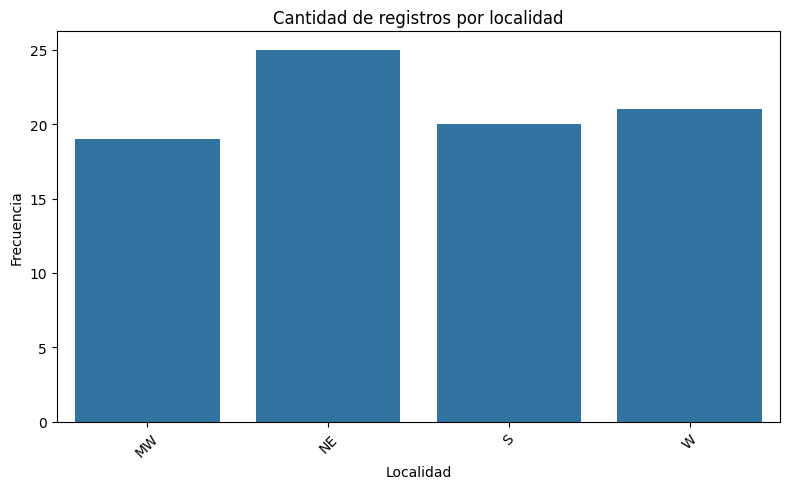

DATAFRAME CON ONE-HOT ENCODING:


,salary,cost,location_NE,location_S,location_W
0,119000,189300,1,0,0
1,121000,189600,1,0,0
2,123000,188400,1,0,0
3,123000,188700,1,0,0
4,110000,194200,1,0,0


COLUMNAS FINALES:
['salary', 'cost', 'location_NE', 'location_S', 'location_W']

INFORMACIÓN DEL DATAFRAME FINAL:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   salary       85 non-null     int64
 1   cost         85 non-null     int64
 2   location_NE  85 non-null     int64
 3   location_S   85 non-null     int64
 4   location_W   85 non-null     int64
dtypes: int64(5)
memory usage: 3.4 KB

DIMENSIONES DEL DATAFRAME:
(85, 5)


In [ ]:

# 1. CARGA DE DATOS


# Conectar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

# Cargar el archivo college.csv desde la carpeta Unidad02
df = pd.read_csv('/content/drive/MyDrive/Unidad02/college.csv')

print("DATOS ORIGINALES:")
display(df.head())




# 2. SELECCIÓN DE VARIABLES


# Seleccionar únicamente las columnas necesarias:
# salary = variable dependiente
# cost = variable independiente numérica
# location = variable independiente categórica

df = df[['salary', 'cost', 'location']].copy()

print("COLUMNAS SELECCIONADAS:")
display(df.head())



# 3. CONVERSIÓN DE LOCATION A VARIABLE CATEGÓRICA


# Convertir location al tipo de dato category

df['location'] = df['location'].astype('category')

print("TIPOS DE DATOS:")
print(df.dtypes)



# 4. ESTADÍSTICAS DESCRIPTIVAS DE SALARY Y COST


# Obtener cantidad, promedio, desviación estándar,
# mínimo, cuartiles y máximo de ambas variables

print("ESTADÍSTICAS DESCRIPTIVAS:")
display(df[['salary', 'cost']].describe())



# 5. CONTEO DE DATOS POR CATEGORÍA EN LOCATION

# Contar cuántos registros existen en cada localidad

print("CANTIDAD DE REGISTROS POR LOCALIDAD:")
print(df['location'].value_counts())



# 6. GRÁFICA DE FRECUENCIAS DE LOCATION


# Representar gráficamente la cantidad de registros
# correspondientes a cada localidad

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='location')
plt.title('Cantidad de registros por localidad')
plt.xlabel('Localidad')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



# 7. ONE-HOT ENCODING K-1


# Convertir location en variables dummy.
# drop_first=True elimina una categoría de referencia
# para evitar multicolinealidad perfecta.

df_encoded = pd.get_dummies(
    df,
    columns=['location'],
    drop_first=True,
    dtype=int
)

print("DATAFRAME CON ONE-HOT ENCODING:")
display(df_encoded.head())



# 8. COMPROBAR EL RESULTADO FINAL


# Mostrar las columnas resultantes y sus tipos de datos

print("COLUMNAS FINALES:")
print(df_encoded.columns.tolist())

print("\nINFORMACIÓN DEL DATAFRAME FINAL:")
df_encoded.info()

print("\nDIMENSIONES DEL DATAFRAME:")
print(df_encoded.shape)


1. Carga de datos
En esta primera parte conecto mi Google Drive con Google Colab para poder acceder al archivo college.csv, que se encuentra guardado en la carpeta Unidad02. Después importo las librerías necesarias y cargo el archivo en un DataFrame de Pandas para poder trabajar con los datos.

2. Selección de variables
En esta parte selecciono únicamente las tres columnas que necesito para la práctica: salary, que representa el salario y será mi variable dependiente; cost, que representa el costo y será mi variable independiente numérica; y location, que representa la localidad y será mi variable independiente categórica.

3. Conversión de location a variable categórica
Aquí convierto la columna location al tipo de dato categórico, ya que contiene diferentes localidades y no representa cantidades numéricas. Esto permite que Python identifique correctamente que sus valores son categorías.

4. Estadísticas descriptivas de salary y cost
En esta sección utilizo la función describe() para obtener un resumen estadístico de las variables salary y cost. Con esto puedo conocer la cantidad de datos, el promedio, la desviación estándar, los valores mínimos y máximos, así como los cuartiles de cada variable.

5. Conteo de datos por categoría en location
En esta parte utilizo value_counts() para contar cuántos registros existen en cada localidad. Esto me permite identificar cuántos datos pertenecen a cada categoría y conocer cuáles tienen mayor o menor cantidad de registros.

6. Gráfica de frecuencias de location
Aquí utilizo las librerías Matplotlib y Seaborn para crear una gráfica de barras que muestra la cantidad de registros que existen en cada localidad. Esto me ayuda a visualizar y comparar fácilmente la distribución de los datos por categoría.

7. One-Hot Encoding K-1
En esta sección convierto la variable categórica location en variables dummy mediante One-Hot Encoding. Utilizo drop_first=True para eliminar una de las categorías y tomarla como referencia, evitando así la multicolinealidad perfecta. De esta manera, las localidades quedan representadas mediante valores numéricos de 0 y 1.

8. Comprobar el resultado final
Finalmente, verifico que la transformación se haya realizado correctamente. Muestro las columnas nuevas, los tipos de datos y las dimensiones del DataFrame. Así puedo comprobar que mis variables están preparadas para utilizarlas posteriormente en el modelo de regresión lineal.

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




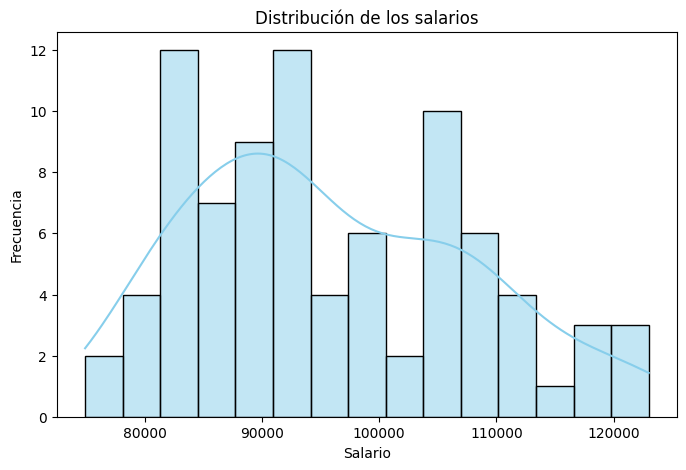

In [ ]:

# HISTOGRAMA DE SALARY

plt.figure(figsize=(8,5))

sns.histplot(data=df, x='salary', bins=15, kde=True, color='skyblue')

plt.title('Distribución de los salarios')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')

plt.show()

Discusión de la gráfica observada:

Sesgo y Multimodalidad: La distribución de los salarios abarca un rango desde aproximadamente 75,000 hasta 125,000. No sigue perfectamente una distribución normal pura, sino que presenta una ligera asimetría positiva (sesgada a la derecha) con múltiples picos/modas (bimodal o multimodal), destacando concentraciones relevantes de frecuencia alrededor de los 82,000–85,000, los 91,000–94,000 y cerca de los 105,000.

Concentración Principal: La mayor densidad de salarios se sitúa entre 80,000 y 110,000. Conforme aumenta el salario por encima de los 110,000, la frecuencia decrece notablemente, siendo los valores superiores a 115,000 los menos comunes.

Interpretación: La presencia de varios picos sugiere que el salario podría estar influenciado o segmentado por subgrupos dentro de los datos (por ejemplo, diferencias asociadas a la variable de ubicación location o al tipo de institución).

---
---
* El codigo utilza `histplot()` para representar la distribución de los salarios. También establezco el tamaño de la gráfica, agrego el título y los nombres de los ejes para facilitar su interpretación. Finalmente, utilizo `show()` para mostrar el resultado.
---
---


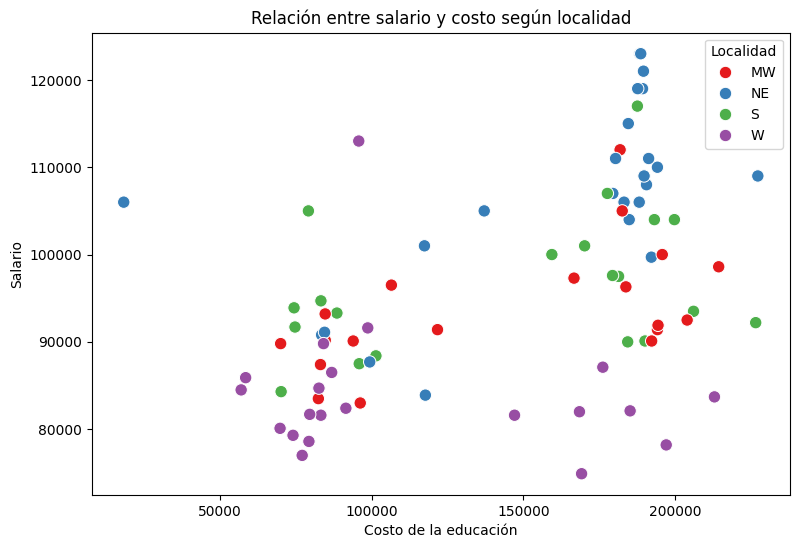

In [ ]:

# DIAGRAMA DE DISPERSIÓN: SALARY VS COST

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x='cost',
    y='salary',
    hue='location',
    palette='Set1',
    s=80
)

plt.title('Relación entre salario y costo según localidad')
plt.xlabel('Costo de la educación')
plt.ylabel('Salario')
plt.legend(title='Localidad')

plt.show()


El diagrama de dispersión muestra una tendencia positiva general donde a mayor costo de la educación, los salarios tienden a ser más altos, destacándose la región NE (azul) con los mayores costos y salarios (superando los $120,000). Por su parte, la región W (morado) se concentra principalmente en costos y salarios más bajos, mientras que las regiones MW (rojo) y S (verde) se distribuyen en dos clústeres diferenciados (costos bajos y altos). Esto evidencia que, aunque existe cierta relación entre el costo y el salario, la ubicación geográfica es un factor determinante en dicha variación.

---
---
* En el codigo se utiliza `scatterplot()` para representar la relación entre el salario y el costo de la educación. Utilizo hue='location' para identificar cada localidad con un color diferente. También agrego el título, los nombres de los ejes y la leyenda para distinguir las categorías.
---
---

/tmp/ipykernel_2265/1617297502.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


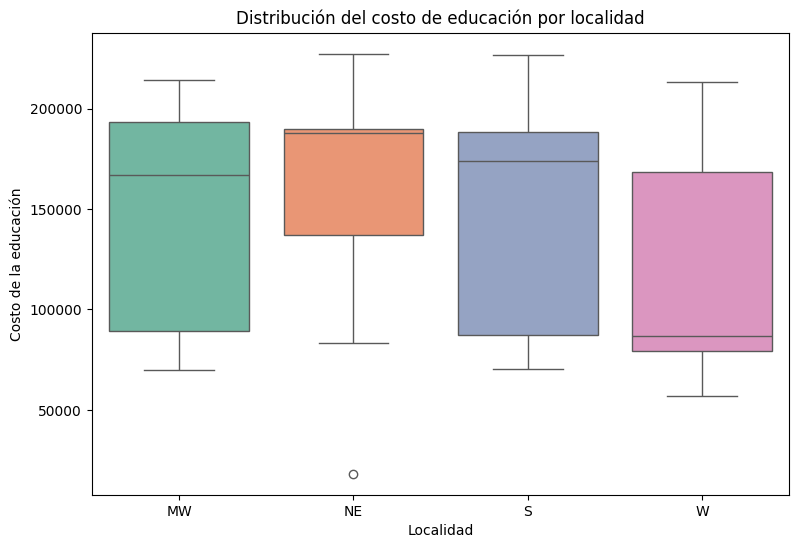

In [ ]:

# BOXPLOT: COSTO SEGÚN LOCALIDAD

plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x='location',
    y='cost',
    palette='Set2'
)

plt.title('Distribución del costo de educación por localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo de la educación')

plt.show()


El diagrama de caja revela que las localidades NE, S y MW presentan los costos de educación más elevados, con medianas cercanas o superiores a los 170,000, destacando la región NE por tener la mayoría de sus instituciones concentradas en el rango de alto costo y un valor atípico atípicamente bajo (menor a 20,000). En contraste, la región W muestra la mediana más baja del estudio (por debajo de 90,000) y una asimetría hacia costos menores, evidenciando que existen diferencias significativas en la distribución del costo educativo según la ubicación geográfica

---
---
* En el cotido se utiliza ` boxplot()` para comparar la distribución de los costos de educación entre las diferentes localidades. Coloco location en el eje horizontal y cost en el eje vertical, además de utilizar distintos colores para diferenciar las categorías. Finalmente, agrego el título y las etiquetas correspondientes para mostrar la gráfica y facilitar la comparación.
---
---

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [ ]:
#Construccion del modelo

# 1. DEFINIR LAS VARIABLES

# Variable dependiente: salary
y = df_encoded['salary']

# Variables independientes: cost y localidades codificadas
X = df_encoded.drop(columns=['salary'])


# 2. CREAR Y ENTRENAR EL MODELO

from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X, y)


# 3. IMPRIMIR EL INTERCEPTO Y LOS COEFICIENTES

print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo.coef_
})

print("\nCoeficientes del modelo:")
display(coeficientes)


# 4. MOSTRAR LA ECUACIÓN DE REGRESIÓN

print("\nEcuación del modelo:")

ecuacion = f"Salary = {modelo.intercept_:.4f}"

for variable, coeficiente in zip(X.columns, modelo.coef_):
    ecuacion += f" + ({coeficiente:.4f} * {variable})"

print(ecuacion)


Intercepto: 84988.71622754404

Coeficientes del modelo:


,Variable,Coeficiente
0,cost,0.060518
1,location_NE,12032.819692
2,location_S,2800.345026
3,location_W,-7721.420103



Ecuación del modelo:
Salary = 84988.7162 + (0.0605 * cost) + (12032.8197 * location_NE) + (2800.3450 * location_S) + (-7721.4201 * location_W)


De acuerdo con los resultados obtenidos, el modelo de regresión tiene un intercepto de 84,988.72 y los siguientes coeficientes:

**Intercepto **(84,988.72): representa el salario estimado para la localidad de referencia, cuando el costo es cero.

**Cost** (0.0605): significa que por cada unidad que aumenta el costo de la educación, el salario estimado aumenta aproximadamente 0.06 unidades, manteniendo constante la localidad.

**Location_NE** (12,032.82): significa que la localidad NE tiene un salario estimado 12,032.82 unidades mayor que la localidad de referencia, manteniendo constante el costo.

**Location_S** (2,800.35): significa que la localidad S tiene un salario estimado 2,800.35 unidades mayor que la localidad de referencia, manteniendo constante el costo.

**Location_W** (-7,721.42): significa que la localidad W tiene un salario estimado 7,721.42 unidades menor que la localidad de referencia, manteniendo constante el costo.


Al observar los resultados puedo identificar que el costo de la educación tiene una relación positiva con el salario, aunque su coeficiente es pequeño. También puedo observar que las localidades NE y S tienen coeficientes positivos, lo que significa que sus salarios estimados son mayores que los de la localidad de referencia. Por otro lado, la localidad W tiene un coeficiente negativo, indicando que sus salarios estimados son menores. Con esto puedo concluir que tanto el costo como la ubicación ayudan a explicar las diferencias en los salarios.

---
---
* En esta parte separo la variable` salary` de las variables independientes `cost` y `location`, que ya está codificada con One-Hot Encoding. Después utilizo `LinearRegression()` para crear el modelo y `fit(X, y)` para entrenarlo con los datos. Con `intercept_` obtengo el valor inicial del modelo y con `coef_` obtengo los coeficientes de cada variable. Finalmente, utilizo un ciclo for para mostrar la ecuación de regresión y poder interpretar cómo se relacionan el costo y la localidad con el salario.
---
---

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

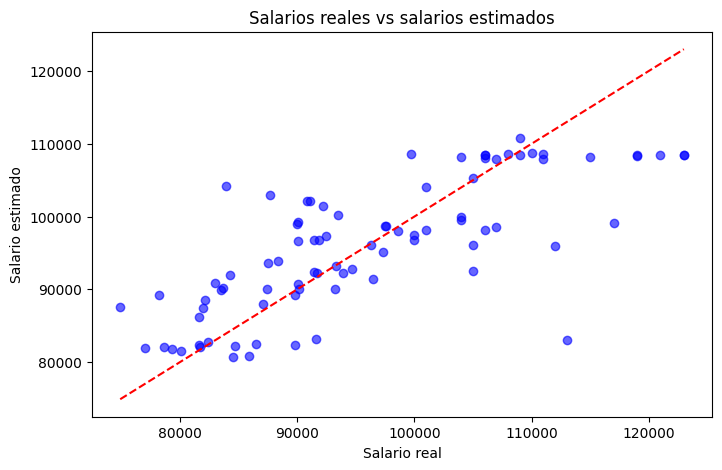

In [ ]:
#Visualización de predicciones: salario estimado vs salario real
# 1. GENERAR PREDICCIONES
y_pred = modelo.predict(X)

# 2. GRAFICAR SALARIOS REALES VS ESTIMADOS
plt.figure(figsize=(8,5))

plt.scatter(y, y_pred, color='blue', alpha=0.6)

# Línea de referencia
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color='red',
    linestyle='--'
)

plt.title('Salarios reales vs salarios estimados')
plt.xlabel('Salario real')
plt.ylabel('Salario estimado')

plt.show()


Interpretacion:

- Tendencia general: Los puntos muestran una relación positiva moderada, lo que indica que el modelo logra capturar una parte de la tendencia de los datos (a mayores salarios reales, estimaciones más altas).

- Limitación o sesgo: Se observa que en los salarios reales más altos (hacia la derecha, superando los 110,000), el modelo subestima considerablemente los valores, ya que las predicciones se estancan o aplanan por debajo de los 110,000 en el eje vertical.

---
---
*  En el codigo utilizo `predict()` para obtener los salarios estimados por el modelo. Después creo una gráfica de dispersión para comparar los salarios reales con los estimados y agrego una línea roja de referencia para identificar qué tan cerca están las predicciones de los valores reales.
---
---

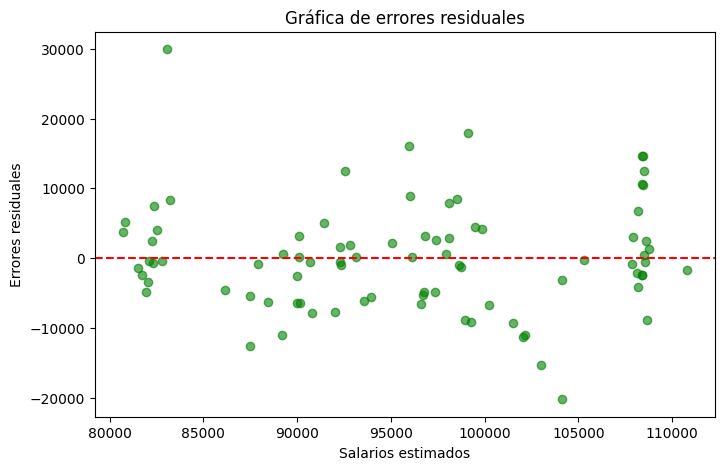

In [ ]:
#Gráfica de errores residuales


# 1. CALCULAR LOS RESIDUOS
residuos = y - y_pred

# 2. GRAFICAR LOS RESIDUOS
plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuos, color='green', alpha=0.6)

# Línea de referencia en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Gráfica de errores residuales')
plt.xlabel('Salarios estimados')
plt.ylabel('Errores residuales')

plt.show()


Intepretacion:
La gráfica de errores residuales muestra la diferencia entre los valores reales y los estimados frente a los salarios predichos. Aunque los puntos se distribuyen alrededor de la línea roja de referencia en cero, se observan desviaciones importantes y valores atípicos notables —como un residuo positivo de cerca de $+30,000$ en salarios bajos y residuos negativos de hasta $-20,000$ en estimaciones intermedias—, lo que indica que el modelo no captura completamente toda la variabilidad de los datos y presenta ciertos sesgos en determinados rangos.

---
---
*  En el codigo calculo los errores residuales restando los salarios estimados a los salarios reales mediante y - y_pred. Después utilizo scatter() para representar los errores en una gráfica y axhline() para agregar una línea de referencia en cero que me permite identificar si los errores son positivos o negativos.
---
---

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [ ]:

# CALCULAR EL MSE
mse = mean_squared_error(y, y_pred)

# CALCULAR EL R² SCORE
r2 = r2_score(y, y_pred)

# Resultados
print("Error cuadrático medio (MSE):", mse)
print("R² Score:", r2)

Error cuadrático medio (MSE): 60480269.14657189
R² Score: 0.5705089716684086


Al observar los resultados, obtuve un MSE de 60,480,269.15, lo que indica que existen diferencias entre los salarios reales y los salarios estimados por el modelo. Por otro lado, el R² Score fue de 0.5705, lo que significa que el modelo logra explicar aproximadamente el 57.05% de la variación de los salarios utilizando las variables costo y localidad. Considero que el modelo tiene un ajuste moderado, ya que logra explicar más de la mitad de las variaciones, pero todavía existen otros factores que pueden influir en los salarios y que no están incluidos en el análisis.

---
---
*  El codigo utiliza `mean_squared_error()` para calcular el promedio de los errores al cuadrado y `r2_score()` para conocer qué proporción de la variación de los salarios explica el modelo.
---
---

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [ ]:

# 1. IMPORTAR LIBRERÍAS
import numpy as np
import pandas as pd
import statsmodels.api as sm

# 2. PREPARAR LOS DATOS
datos = df[['salary', 'cost', 'location']].dropna().copy()

datos['location'] = datos['location'].astype('category')

# 3. DEFINIR EL COMPONENTE DE VARIANZA
vc = {
    "location": "0 + C(location)"
}

# Crear un grupo constante
grupos = np.ones(datos.shape[0])

# 4. CONSTRUIR EL MODELO MIXTO
modelo_mixto = sm.MixedLM.from_formula(
    "salary ~ cost",
    groups=grupos,
    vc_formula=vc,
    data=datos
)

# 5. AJUSTAR EL MODELO
resultado = modelo_mixto.fit()

# 6. MOSTRAR LOS RESULTADOS
print(resultado.summary())

# 7. MOSTRAR LOS COMPONENTES DE VARIANZA
print("\nVarianza de location:", resultado.vcomp)
print("Varianza residual:", resultado.scale)


               Mixed Linear Model Regression Results
Model:                MixedLM   Dependent Variable:   salary       
No. Observations:     85        Method:               REML         
No. Groups:           1         Scale:                64259988.9170
Min. group size:      85        Log-Likelihood:       -883.7724    
Max. group size:      85        Converged:            Yes          
Mean group size:      85.0                                         
-------------------------------------------------------------------
                Coef.     Std.Err.   z    P>|z|   [0.025    0.975] 
-------------------------------------------------------------------
Intercept       86475.116 4755.851 18.183 0.000 77153.819 95796.412
cost                0.063    0.017  3.619 0.000     0.029     0.097
location Var 63375113.891 6902.606                                 


Varianza de location: [63375113.8907166]
Varianza residual: 64259988.916992426


Al observar los resultados del análisis de componentes de varianza, puedo identificar que el costo de la educación tiene una relación positiva con el salario, ya que su coeficiente es de 0.063. Además, su valor p es de 0.000, lo que indica que es estadísticamente significativo. La varianza de la localidad fue de 63,375,113.89, lo que muestra que existen diferencias importantes entre las localidades. Por otro lado, la varianza residual fue de 64,259,988.92, lo que significa que todavía existe una cantidad considerable de variación en los salarios que el modelo no logra explicar. Finalmente, el modelo convergió correctamente, por lo que considero que el análisis permite observar que tanto el costo como la localidad son factores importantes para estudiar las diferencias salariales.

En el codigo utilizo `MixedLM.from_formula()` para construir un modelo lineal mixto, donde analizo la relación del costo con el salario y considero la localidad como un componente de varianza. Con `fit()` ajusto el modelo y finalmente utilizo `summary()` para mostrar los resultados, conocer los coeficientes y observar cuánto varían los salarios según la localidad y los errores que no logra explicar el modelo.